
<h1 align="center">Used Car Price Prediction</h1> 

<h3 align="center">Random Forest Regressor</h3> 

---------------------------------------------------------------------------------------------------------------------------

In [1]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

sns.set() # all plot will cover on seaborn style

In [2]:
car = pd.read_csv('Data/Car_cleaned_with_Model.csv')

In [3]:
car.head()

,Brand,Price,Body,Mileage,EngineV,Engine Type,Registration,Year,Model
0,BMW,4200.0,sedan,277,2.0,Petrol,yes,1991,320
1,Mercedes-Benz,7900.0,van,427,2.9,Diesel,yes,1999,Sprinter 212
2,Mercedes-Benz,13300.0,sedan,358,5.0,Gas,yes,2003,S 500
3,Audi,23000.0,crossover,240,4.2,Petrol,yes,2007,Q7
4,Toyota,18300.0,crossover,120,2.0,Petrol,yes,2011,Rav 4


#### Now I will create dictionary for every categorical column to store their dummy values for each categorical label. It will be used later during web app creation.

I am storing categorical label information so that later the web app can convert user input into model-understandable encoded values.

In [5]:
# creating dictionary for every categoricla column

brand_dic = dict()
body_dic = dict()
engine_type_dic = dict()
registration_dic = dict()
model_dic =dict()

In [6]:
from sklearn.preprocessing import LabelEncoder

# creating an instance of the labelEncoder
le = LabelEncoder()

# Brand column
car['brand_enc'] = le.fit_transform(car['Brand'])     # Encode Brand column into numerical labels.
for num, lbl in enumerate(le.classes_):               
  brand_dic[lbl] = num                                # Store label-to-number mapping in dictionary.


# Body column
car['body_enc'] = le.fit_transform(car['Body'])
for num, lbl in enumerate(le.classes_):
  body_dic[lbl] = num


# Engine type
car['engine_type_enc'] = le.fit_transform(car['Engine Type'])
for num, lbl in enumerate(le.classes_):
  engine_type_dic[lbl]=num

# Registration column
car['regis_enc'] = le.fit_transform(car['Registration'])
for num, lbl in enumerate(le.classes_):
  registration_dic[lbl]=num

# Model
car['model_enc'] = le.fit_transform(car['Model'])
for num, lbl in enumerate(le.classes_):
  model_dic[lbl]=num

# droping the old categorical column
car_2 = car.drop(['Brand', 'Body', 'Engine Type', 'Registration', 'Model'], axis=1)

car_2.head()

,Price,Mileage,EngineV,Year,brand_enc,body_enc,engine_type_enc,regis_enc,model_enc
0,4200.0,277,2.0,1991,1,3,3,1,17
1,7900.0,427,2.9,1999,2,5,0,1,248
2,13300.0,358,5.0,2003,2,3,1,1,222
3,23000.0,240,4.2,2007,0,0,3,1,211
4,18300.0,120,2.0,2011,5,0,3,1,214


#### Now as It known that `tree` based model are very powerfull and also the ensemble approch `RandomForest` is very powerfull and mostely used machine learning algorithms. The main advantage it is not required to longer data preprocessing, and also gives better result.

In [7]:
X = car_2.drop('Price', axis=1)
y = car_2['Price']

In [8]:
X.shape, y.shape

((3867, 8), (3867,))

In [10]:
# train test split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

In [11]:
X_train.shape, y_train.shape, X_test.shape, y_test.shape

((3093, 8), (3093,), (774, 8), (774,))

In [12]:
# importing RandomForest Regressor
from sklearn.ensemble import  RandomForestRegressor

# creating instance of randomforest regressor
rf_1 = RandomForestRegressor()

# checking the hyperparameter of the randomforest 
rf_1.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'criterion': 'squared_error',
 'max_depth': None,
 'max_features': 1.0,
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': None,
 'oob_score': False,
 'random_state': None,
 'verbose': 0,
 'warm_start': False}

In [13]:
# First i will create a base model then i will go for hyperparameter tuning.
rf_1.fit(X_train, y_train)

RandomForestRegressor()

In [14]:
# performance check on training data
y_pred_train = rf_1.predict(X_train)

# importing the rmse from sklearn
from sklearn.metrics import  mean_squared_error

rmse_train = np.sqrt(mean_squared_error(y_train, y_pred_train))

print('RMSE on Traning data {}'.format(rmse_train))

RMSE on Traning data 2005.6376785088967


In [15]:
# error on testing data
y_pred_test = rf_1.predict(X_test)

rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))

print('RMSE on Testing data {}'.format(rmse_test))

RMSE on Testing data 4590.105703162648


In [16]:
# chceking the socre on traning data.
from sklearn.metrics import r2_score

y_pred_train = rf_1.predict(X_train)

print('Traning Score: {}'.format(r2_score(y_train, y_pred_train)))

Traning Score: 0.9887649029798982


In [17]:
# chceking the socre for testing.

y_pred_test = rf_1.predict(X_test)
print('Testing Score: {}'.format(r2_score(y_test, y_pred_test)))

Testing Score: 0.9457697315654869


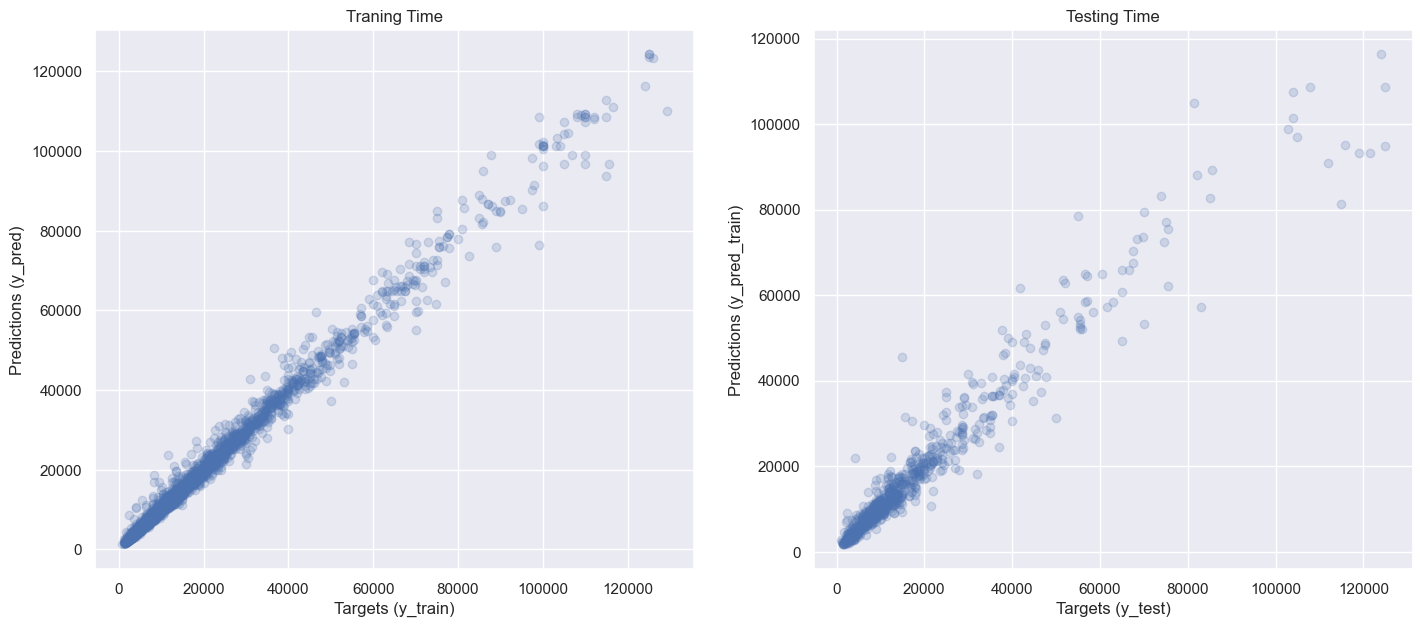

In [18]:
# plotting the traning
# check the prediction with the original values

plt.figure(figsize=(17,7))

y_pred_train = rf_1.predict(X_train)
plt.subplot(1,2,1)
plt.scatter(y_train, y_pred_train, alpha=0.2);
plt.xlabel('Targets (y_train)');
plt.ylabel('Predictions (y_pred)');
plt.title('Traning Time');

# plotting testing error
y_pred_test = rf_1.predict(X_test)
plt.subplot(1,2,2)
plt.scatter(y_test, y_pred_test, alpha=0.2);
plt.xlabel('Targets (y_test)');
plt.ylabel('Predictions (y_pred_train)');
plt.title('Testing Time');

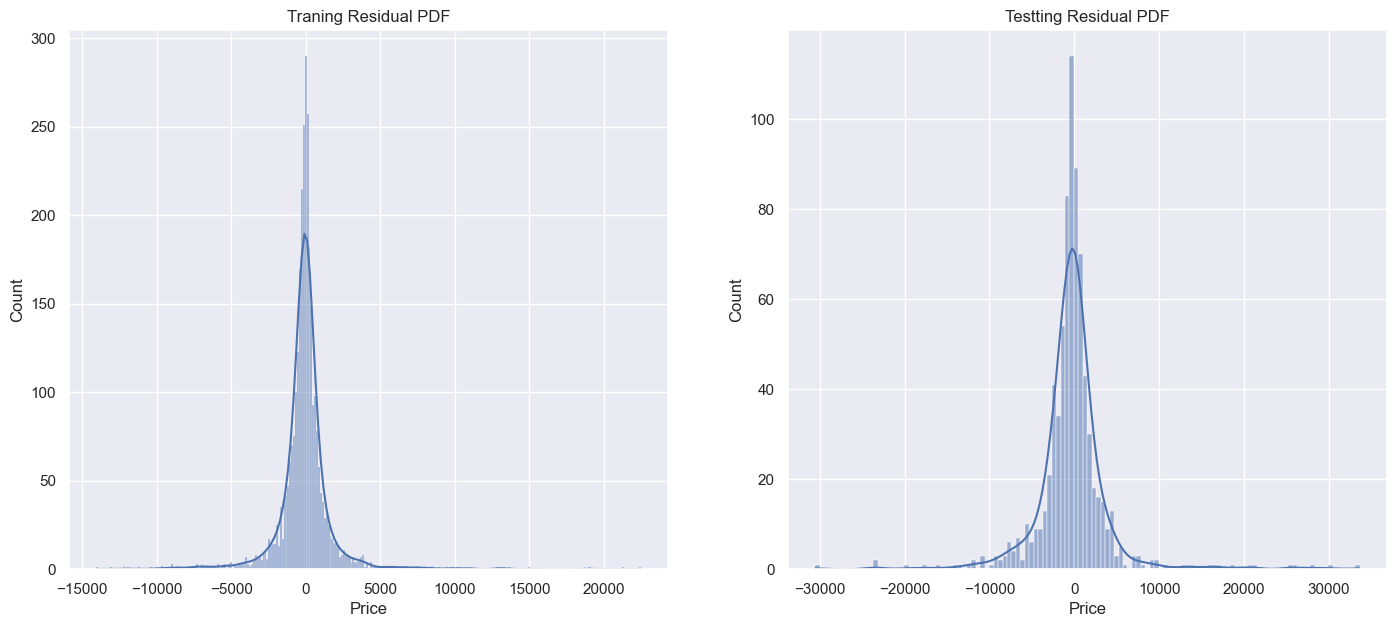

In [19]:
# plotting the distribution of the residual
residual_train = (y_train - rf_1.predict(X_train))
residual_test = (y_test - rf_1.predict(X_test))

# ploting the distribution of the residual on training
plt.figure(figsize=(17,7))

plt.subplot(1,2,1)
sns.histplot(residual_train, kde=True);
plt.title('Traning Residual PDF');

# ploting the distribution of the residual on testing
plt.subplot(1,2,2)
sns.histplot(residual_test, kde=True);
plt.title('Testting Residual PDF');

In [20]:
# Creating a dataframe to compare the result and prediction.
df_eval = pd.DataFrame(rf_1.predict(X_test), columns=['Prediction'])

# adding column
y_test = y_test.reset_index(drop=True)
df_eval['Target'] = y_test

# creating residual columns and difference column
df_eval['Residual'] = df_eval['Target'] - df_eval['Prediction']
df_eval['Difference%'] = np.absolute(df_eval['Residual'] / df_eval['Target']*100)

# checking the performance data 
df_eval

,Prediction,Target,Residual,Difference%
0,28810.500,21300.0,-7510.500,35.260563
1,8363.000,8900.0,537.000,6.033708
2,5329.185,3250.0,-2079.185,63.974923
3,13585.300,12000.0,-1585.300,13.210833
4,3896.470,5400.0,1503.530,27.843148
...,...,...,...,...
769,4238.500,4200.0,-38.500,0.916667
770,8996.420,8800.0,-196.420,2.232045
771,4580.260,4850.0,269.740,5.561649
772,21474.190,27000.0,5525.810,20.465963


In [21]:
# description of the eval_df
df_eval.describe()

,Prediction,Target,Residual,Difference%
count,774.000000,774.000000,774.000000,774.000000
mean,18059.922439,17799.988992,-259.933446,17.658732
std,18774.535523,19723.434542,4585.703196,27.687709
min,1661.150000,999.000000,-30540.980000,0.023196
25%,7133.492500,6700.000000,-1564.447500,4.854785
50%,11357.782857,11050.000000,-234.950000,11.107590
75%,20898.285000,20475.000000,850.268125,21.384919
max,116269.812444,125000.000000,33611.250000,421.000000


### Now I will tune the `hyperparameter` to make more generalize model.

In [22]:
# starting hyperparameter tuning

# performing hyperparameter tuning with RandomizedSearchCV
from sklearn.model_selection import RandomizedSearchCV

# creating instance of RandomForest 
rf_random = RandomForestRegressor()

# creating random parameter
random_grid = {'bootstrap': [True, False],
 'max_depth': [10, 20, 30, 40, 50, None], # maximum number of levels in each decision tree
 'max_features': ['auto', 'sqrt'],
 'min_samples_leaf': [1, 2, 4],
 'min_samples_split': [2, 5, 7],
 'n_estimators': [100,200]} # how many decision trees

# create an instance of randomsearch csv
rf_random = RandomizedSearchCV(estimator=rf_random,
                               param_distributions=random_grid,
                               n_iter=100,
                               cv=3,
                               verbose=8,
                               n_jobs=-1)

# starting the search
rf_random.fit(X_train, y_train)

Fitting 3 folds for each of 100 candidates, totalling 300 fits


RandomizedSearchCV(cv=3, estimator=RandomForestRegressor(), n_iter=100,
                   n_jobs=-1,
                   param_distributions={'bootstrap': [True, False],
                                        'max_depth': [10, 20, 30, 40, 50, None],
                                        'max_features': ['auto', 'sqrt'],
                                        'min_samples_leaf': [1, 2, 4],
                                        'min_samples_split': [2, 5, 7],
                                        'n_estimators': [100, 200]},
                   verbose=8)

In [23]:
rf_random.best_estimator_, rf_random.best_params_, rf_random.best_score_

(RandomForestRegressor(bootstrap=False, max_features='sqrt', n_estimators=200),
 {'n_estimators': 200,
  'min_samples_split': 2,
  'min_samples_leaf': 1,
  'max_features': 'sqrt',
  'max_depth': None,
  'bootstrap': False},
 np.float64(0.9272364311784411))

In [24]:
# checkng traning error
np.sqrt(mean_squared_error(y_train, rf_random.predict(X_train)))

np.float64(547.897974337041)

In [25]:
# checking the testing error
np.sqrt(mean_squared_error(y_test, rf_random.predict(X_test)))

np.float64(4081.619496498437)

#### Looks like the model is still on overfit. It make traning error is `547` and testing error `4081`.

#### Now I will try with `GridSearchCV`

In [26]:
# importing GridSearchCV cv
from sklearn.model_selection import GridSearchCV

# create an instance of new model
rf_grid_model = RandomForestRegressor()


param_grid =  {'bootstrap': [False],
  'max_depth': [25,30,35],
  'max_features': ['sqrt'],
  'min_samples_leaf': [1,2],
  'min_samples_split': [1,2,3],
  'n_estimators': [100,150,200]}


# searchin for best paramete from neighbour of random search cv parameter
rf_grid = GridSearchCV(estimator=rf_grid_model,
                       param_grid=param_grid,
                       cv=3,
                       n_jobs=-1,
                       verbose=8)


# fitting on data
rf_grid.fit(X_train, y_train)

Fitting 3 folds for each of 54 candidates, totalling 162 fits


GridSearchCV(cv=3, estimator=RandomForestRegressor(), n_jobs=-1,
             param_grid={'bootstrap': [False], 'max_depth': [25, 30, 35],
                         'max_features': ['sqrt'], 'min_samples_leaf': [1, 2],
                         'min_samples_split': [1, 2, 3],
                         'n_estimators': [100, 150, 200]},
             verbose=8)

In [27]:
rf_grid.best_estimator_, rf_grid.best_params_, rf_grid.best_score_

(RandomForestRegressor(bootstrap=False, max_depth=25, max_features='sqrt',
                       min_samples_split=3, n_estimators=200),
 {'bootstrap': False,
  'max_depth': 25,
  'max_features': 'sqrt',
  'min_samples_leaf': 1,
  'min_samples_split': 3,
  'n_estimators': 200},
 np.float64(0.9286877222747973))

In [28]:
# checkng traning error
np.sqrt(mean_squared_error(y_train, rf_grid.predict(X_train)))

np.float64(958.8558951808071)

In [29]:
# checking the testing error
np.sqrt(mean_squared_error(y_test, rf_random.predict(X_test)))

np.float64(4081.619496498437)

Looks like the problem arise on the total no of Decision tree on the internal model. The `n_estimators` hyper-parameter is want to decrease lowering the variance.

As i notice the all parameter works great but lower the `n_estimators`. The traning error is increased. So here i need to increase liitle bit traning error for lowering the variance.

#### Again i will try GridSearchCV for find the best model

In [30]:
# create an instance of new model
rf_grid_model_2 = RandomForestRegressor()


param_grid_2 =  {'bootstrap': [False],
  'max_depth': [28,30,32],
  'max_features': ['sqrt'],
  'min_samples_leaf': [1],
  'min_samples_split': [2,3,4],
  'n_estimators': [50,80,100]}


# searchin for best paramete from neighbour of random search cv parameter
rf_grid_2 = GridSearchCV(estimator=rf_grid_model_2,
                       param_grid=param_grid_2,
                       cv=3,
                       n_jobs=-1,
                       verbose=8)


# fitting on data
rf_grid_2.fit(X_train, y_train)

Fitting 3 folds for each of 27 candidates, totalling 81 fits


GridSearchCV(cv=3, estimator=RandomForestRegressor(), n_jobs=-1,
             param_grid={'bootstrap': [False], 'max_depth': [28, 30, 32],
                         'max_features': ['sqrt'], 'min_samples_leaf': [1],
                         'min_samples_split': [2, 3, 4],
                         'n_estimators': [50, 80, 100]},
             verbose=8)

In [31]:
rf_grid_2.best_estimator_, rf_grid_2.best_params_, rf_grid_2.best_score_

(RandomForestRegressor(bootstrap=False, max_depth=28, max_features='sqrt',
                       min_samples_split=3),
 {'bootstrap': False,
  'max_depth': 28,
  'max_features': 'sqrt',
  'min_samples_leaf': 1,
  'min_samples_split': 3,
  'n_estimators': 100},
 np.float64(0.9286195516075599))

In [32]:
# Checking traning error.
np.sqrt(mean_squared_error(y_train, rf_grid_2.predict(X_train)))

np.float64(956.7288490903435)

In [33]:
# checking testing error
np.sqrt(mean_squared_error(y_test, rf_grid_2.predict(X_test)))

np.float64(4097.3789972885215)

#### Now this model can be used, although this is not much generalize error, there is lot difference in traning error and testing error. Now i will go detail evalute process with this model `rf_grid_2`

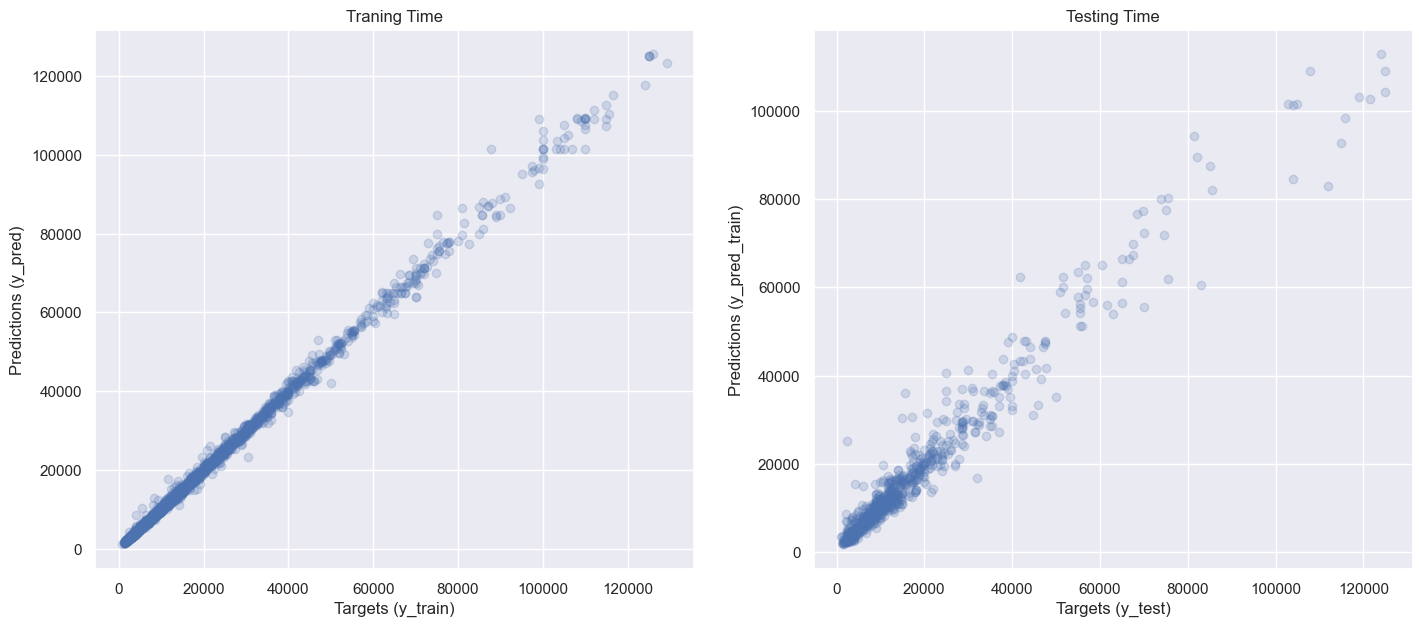

In [34]:
# plotting the traning
# check the prediction with the original values
plt.figure(figsize=(17,7))

y_pred_train = rf_grid_2.predict(X_train)
plt.subplot(1,2,1)
plt.scatter(y_train, y_pred_train, alpha=0.2);
plt.xlabel('Targets (y_train)');
plt.ylabel('Predictions (y_pred)');
plt.title('Traning Time');

# plotting testing error
y_pred_test = rf_grid_2.predict(X_test)
plt.subplot(1,2,2)
plt.scatter(y_test, y_pred_test, alpha=0.2);
plt.xlabel('Targets (y_test)');
plt.ylabel('Predictions (y_pred_train)');
plt.title('Testing Time');


#### The traning error is very  less.

In [35]:
# checking the score of the last model
from sklearn.metrics import r2_score

print(f'Traning r2_score: {r2_score(y_train, rf_grid_2.predict(X_train))}')
print(f'Testing r2_score: {r2_score(y_test, rf_grid_2.predict(X_test))}')

Traning r2_score: 0.9974434775717501
Testing r2_score: 0.9567875734371882


# Now checking the residual

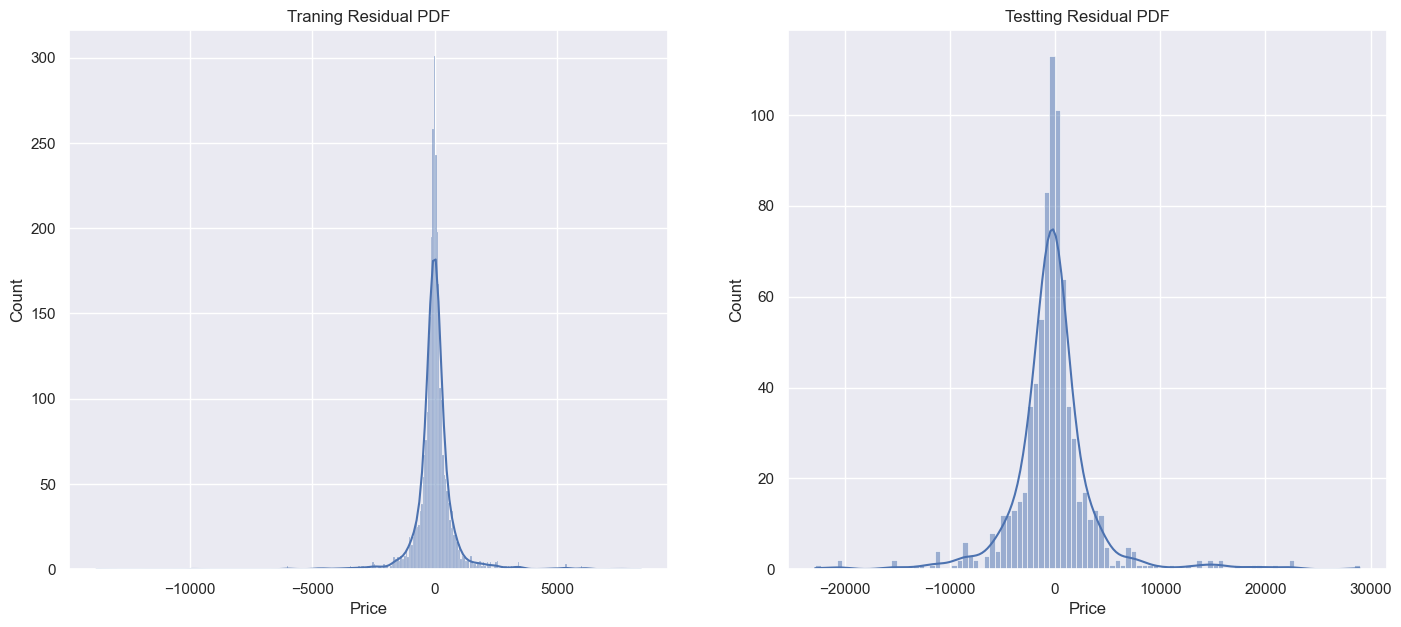

In [36]:
# plotting the distribution of the residual
residual_train = (y_train - rf_grid_2.predict(X_train))
residual_test = (y_test - rf_grid_2.predict(X_test))

# ploting the distribution of the residual on training
plt.figure(figsize=(17,7))

plt.subplot(1,2,1)
sns.histplot(residual_train, kde=True);
plt.title('Traning Residual PDF');

# ploting the distribution of the residual
plt.subplot(1,2,2)
sns.histplot(residual_test, kde=True);
plt.title('Testting Residual PDF');

Not that much Bad, and far better than `Linear Regression`.

Most of the data are lie on `0`, it means most of the cases it makes right decision.

In [37]:
# Creating a dataframe to compare the result and prediction.
df_eval = pd.DataFrame(rf_grid_2.predict(X_test), columns=['Prediction'])

# adding column
y_test = y_test.reset_index(drop=True)
df_eval['Target'] = y_test

# creating residual columns and difference column
df_eval['Residual'] = df_eval['Target'] - df_eval['Prediction']
df_eval['Difference%'] = np.absolute(df_eval['Residual'] / df_eval['Target']*100)

# checking the performance data 
df_eval

,Prediction,Target,Residual,Difference%
0,24648.89000,21300.0,-3348.89000,15.722488
1,8337.74000,8900.0,562.26000,6.317528
2,7384.45500,3250.0,-4134.45500,127.214000
3,12677.38500,12000.0,-677.38500,5.644875
4,4833.49125,5400.0,566.50875,10.490903
...,...,...,...,...
769,4380.00000,4200.0,-180.00000,4.285714
770,9001.37000,8800.0,-201.37000,2.288295
771,3839.23500,4850.0,1010.76500,20.840515
772,20065.38000,27000.0,6934.62000,25.683778


In [38]:
df_eval.describe()

,Prediction,Target,Residual,Difference%
count,774.000000,774.000000,774.000000,774.000000
mean,18025.577821,17799.988992,-225.588828,19.577123
std,18623.084553,19723.434542,4093.809612,43.869515
min,1784.455000,999.000000,-22809.590000,0.000000
25%,7286.077500,6700.000000,-1547.826875,4.544238
50%,11409.855000,11050.000000,-315.725000,11.268282
75%,20764.033750,20475.000000,832.333062,20.611204
max,112764.730000,125000.000000,28938.825000,950.399583


The `Difference%` column is only interest, the differenc is far better than `Linear Regression`

## The above model is overfit .So, choose to use the first base model.

In [39]:
import joblib

# saving the first base model.
joblib.dump(rf_1, 'rf1_base_rf.pkl', compress=3)

['rf1_base_rf.pkl']